In [ ]:
!pip install pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 27.6 MB/s eta 0:00:00


In [ ]:
!pip install linearmodels -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.3 MB/s eta 0:00:00


In [ ]:
# Подключаем нужные библиотеки
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import pyreadstat
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS
from linearmodels.iv import IV2SLS
import statsmodels.api as sm
from scipy.stats import norm

plt.style.use("seaborn-v0_8")

In [ ]:
cpi_yoy = {
    2010: 108.78,
    2011: 106.10,
    2012: 106.57,
    2013: 106.47,
    2014: 111.35,
    2015: 112.91,
    2016: 105.39,
    2017: 102.51,
    2018: 104.26,
    2019: 103.04,
    2020: 104.91,
    2021: 108.39,
    2022: 111.94,
    2023: 107.42,
    2024: 109.52
} #ипц росстат

In [ ]:
deflator = {2010: 1}

for y in range(2011, 2025):
    deflator[y] = deflator[y-1] * (cpi_yoy[y] / 100)

# округлить (не обязательно)
deflator = {k: round(v, 3) for k, v in deflator.items()}

print(deflator)

{2010: 1, 2011: 1.061, 2012: 1.131, 2013: 1.204, 2014: 1.341, 2015: 1.514, 2016: 1.595, 2017: 1.635, 2018: 1.705, 2019: 1.757, 2020: 1.843, 2021: 1.998, 2022: 2.236, 2023: 2.402, 2024: 2.631}


In [ ]:
wave_prefix = {
    2024: 'cc',
    2023: 'bb',
    2022: 'aa',
    2021: 'z',
    2020: 'y',
    2019: 'x',
    2018: 'w',
    2017: 'v',
    2016: 'u',
    2015: 't',
    2014: 's',
    2013: 'r',
    2012: 'q',
    2011: 'p',
    2010: 'o',
}

In [ ]:
df = pd.read_stata(f'r33.dta', convert_categoricals=False)
df.idind

,idind
0,92.0
1,108.0
2,112.0
3,125.0
4,126.0
...,...
11995,65365.0
11996,65366.0
11997,65367.0
11998,65368.0


In [ ]:
df, meta = pyreadstat.read_sav("r19.sav")
print(*df.columns)

idind oredid_i oid_i oid_h nid_i nid_h mid_i mid_h lid_i lid_h kid_i kid_h jid_i jid_h iid_i iid_h hid_i hid_h gid_i gid_h fid_i fid_h eid_i eid_h did_i did_h cid_i cid_h bid_i bid_h aid_i aid_h o_origsm o_inwgt psu region ssu status popul o_int_y o_adult o_child o_marst o_occup08 o_educ o_diplom o_diplom_1 site oh3 oh4 oh4.1 oh5 o_born_m oh6 o_age oh7.1 oh7.2 oh8a oh8b oi1 oi2 oi3 oi3.1 oi4 oi7 oi8 oj1 oj1.1.1 oj1.1.2 oj1.1.3 oj1.1.4 oj2cod08 oj4.2 oj4.3 oj4.1 oj5a oj5b oj5.2 oj6 oj6.0 oj6.1a oj6.1b oj6.2 oj7 oj7.1 oj8 oj8.1 oj8.2 oj8.3 oj9 oj10 oj10.1 oj10.2 oj11 oj11.1 oj11.2 oj13 oj13.2 oj14 oj15 oj16 oj18.2 oj19 oj21.1.1 oj21.1.2 oj21.1.3 oj21.1.4 oj21.1.5 oj21.1.6 oj21.1.7 oj21.1.8 oj21.1.9 oj211.12 oj211.11 oj21a oj21b oj21.3 oj21.4 oj23 oj24 oj25 oj26 oj29 oj308 oj309 oj22 oj29.0 oj31 oj29.1 oj29.2.1 oj29.2.2 oj29.2.3 oj32 oj32.1 oj33cod08 oj35.1 oj36.1a oj36.1b oj36.2 oj37 oj38 oj39 oj40 oj41 oj41.1 oj41.2 oj313 oj314 oj43 oj48.3.1 oj48.3.2 oj48.3.3 oj48.3.4 oj48.3.5 oj48.3.6 

## Построение таблиц

In [ ]:
def educ_cat(x):
    if pd.isna(x):
        return np.nan
    x = int(x)

    if x == 1:
        return "less_secondary"
    if x == 2:
        return "secondary"
    if x in [3, 4, 5]:
        return "ptu"
    if x in [6, 15]:
        return "college"
    if x in [7,8,9,10, 11, 12, 13, 14, 16, 17]:
        return "higher"

    return np.nan

def is_special_missing_value(x):
    if pd.isna(x):
        return False

    try:
        x = int(x)
    except Exception:
        return False

    s = str(abs(x))

    return len(s) >= 2 and set(s[:-1]) == {"9"} and s[-1] in {"6", "7", "8", "9"}

tenure_bins = [-np.inf, 1, 2, 5, 10, 20, np.inf]
tenure_labels = ["до 1", "1-2", "2-5", "5-10", "10-20", "более 20"]

firm_bins = [-np.inf, 11, 51, 101, 501, 1001, np.inf]
firm_labels = ["до 11", "11-50", "51-100", "101-500", "501-1000", "более 1000"]


def process_wave(year):
    w_pref = wave_prefix[year]
    w_num = year - 1991

    if year > 2015:
        df = pd.read_stata(f"r{w_num}.dta", convert_categoricals=False)
    else:
        df, meta = pyreadstat.read_sav(f"r{w_num}.sav")

    df.columns = df.columns.str.lower().str.replace(".", "_", regex=False)

    cols = {
        "idind": "person_id",
        f"{w_pref}j69_9b": "birth_month",
        f"{w_pref}j69_9c": "birth_year",
        f"{w_pref}j13_2": "wage_month",
        f"{w_pref}h5": "sex",
        f"{w_pref}j6_2": "work_hours",
        f"{w_pref}j5a": "tenure_start_y",
        f"{w_pref}j5b": "tenure_start_m",
        f"{w_pref}j72_18a": "educ_raw",
        f"{w_pref}h7_2": "interview_m",
        f"{w_pref}j13": "firm_size",
        f"{w_pref}j23": "state_owned",
        f"{w_pref}j1": "work_status",
        f"{w_pref}j29_1": "job_change",
        f"{w_pref}j11": "org_status",
        f"{w_pref}j72_171": "children_raw",
        f"{w_pref}l5": "health_problem_raw",
    }

    if year > 2012:
        cols[f"{w_pref}j161_3y"] = "exp_y"
        cols[f"{w_pref}j161_3m"] = "exp_m"
    else:
        cols[f"{w_pref}j161_1y"] = "exp_y_before2002"
        cols[f"{w_pref}j161_1m"] = "exp_m_before2002"
        cols[f"{w_pref}j161_2y"] = "exp_y_after2002"
        cols[f"{w_pref}j161_2m"] = "exp_m_after2002"

    existing_cols = [c for c in cols if c in df.columns]
    df = df[existing_cols].rename(columns=cols).copy()

    for col in df.columns:
      df[col] = pd.to_numeric(df[col], errors="coerce")
      df.loc[df[col].apply(is_special_missing_value), col] = np.nan

    df["year"] = year

    #Возраст
    df["age"] = df["year"] - df["birth_year"]

    # Занятость: 1 работает, 3 оплачиваемый отпуск, 4 неоплачиваемый отпуск
    df["employed"] = df["work_status"].isin([1, 3, 4]).astype(int)


    # Зарплата
    df['wage_month'] = df['wage_month'] / deflator[year]
    df["ln_wage"] = np.log(df["wage_month"].where(df["wage_month"] > 0))

    # Пол
    df["male"] = np.where(df["sex"] == 1, 1, np.where(df["sex"] == 2, 0, np.nan))
    df["female"] = np.where(df["sex"] == 2, 1, np.where(df["sex"] == 1, 0, np.nan))

    # Рабочие часы
    df["ln_hours"] = np.log(df["work_hours"].where(df["work_hours"] > 0))

    # Общий трудовой стаж
    if year <= 2012:
        df["experience"] = (
            df.get("exp_y_before2002", np.nan) + df.get("exp_m_before2002", np.nan) / 12
            + df.get("exp_y_after2002", np.nan) + df.get("exp_m_after2002", np.nan) / 12
        )
    else:
        df["experience"] = df.get("exp_y", np.nan) + df.get("exp_m", np.nan) / 12

    df.loc[(df["experience"] < 0) | (df["experience"] > 60), "experience"] = np.nan
    df["experience2"] = df["experience"] ** 2


    df["tenure_start_m_imputed"] = df["tenure_start_m"]

    df.loc[
        df["tenure_start_m_imputed"].isna()
        & df["tenure_start_y"].notna(),
        "tenure_start_m_imputed"
    ] = 6

    # Специальный стаж
    df["tenure"] = (
        df["year"]
        - df["tenure_start_y"]
        + (df["interview_m"] - df["tenure_start_m_imputed"]) / 12
    )

    df.loc[(df["tenure"] < 0) | (df["tenure"] > 60) | (df["tenure"] > df["age"] - 15), "tenure"] = np.nan #про 15 из Ощепкова
    df["tenure2"] = df["tenure"] ** 2

    df["tenure_cat"] = pd.cut(
        df["tenure"],
        bins=tenure_bins,
        labels=tenure_labels,
        right=False
    )

    # Образование
    df["educ_cat"] = df["educ_raw"].apply(educ_cat)
    df["educ_cat"] = pd.Categorical(
        df["educ_cat"],
        categories=["less_secondary", "secondary", "ptu", "college", "higher"]
    )

    # Государственный сектор
    df["state_owned"] = np.where(
        df["state_owned"] == 1, 1,
        np.where(df["state_owned"] == 2, 0, np.nan)
    )

    # Размер фирмы
    df["firm_size"] = pd.to_numeric(df["firm_size"], errors="coerce")
    df["firm_size_cat"] = pd.cut(
        df["firm_size"],
        bins=firm_bins,
        labels=firm_labels,
        right=False
    )

    # Смена работы
    df["mobility"] = (df["tenure"] < 1).astype(int)

    # Наемный работник организации:
    # j11: 1 — работает на предприятии/в организации,
    # 2 — не на предприятии,
    # 3 — самозанятый,
    # 4 — владелец ИП без работников
    df["org_worker"] = np.where(
    df["org_status"] == 1, 1,
    np.where(
        df["org_status"].isin([2, 3, 4]), 0,
        np.nan
    )
    )

    # Наличие детей:
    # j72.171: 1 — есть дети, 2 — нет
    df["has_children"] = np.where(
        df["children_raw"] == 1, 1,
        np.where(df["children_raw"] == 2, 0, np.nan)
    )

    # Проблемы со здоровьем за последние 30 дней:
    # l5: 1 — да, 2 — нет
    df["health_problem"] = np.where(
        df["health_problem_raw"] == 1, 1,
        np.where(df["health_problem_raw"] == 2, 0, np.nan)
    )


    return df

In [ ]:
years = list(range(2010, 2025))

all_waves = []
for year in years:
    print(f"processing {year}")
    one_year = process_wave(year)
    all_waves.append(one_year)

df_all = pd.concat(all_waves, ignore_index=True)

cols_to_drop = [
    "exp_y", "exp_m",
    "exp_y_before2002", "exp_m_before2002",
    "exp_y_after2002", "exp_m_after2002"
]

df_all = df_all.drop(columns=[c for c in cols_to_drop if c in df_all.columns])

processing 2010
processing 2011
processing 2012
processing 2013
processing 2014
processing 2015
processing 2016
processing 2017
processing 2018
processing 2019
processing 2020
processing 2021
processing 2022
processing 2023
processing 2024


In [ ]:
# Выборка A — базовая:
# все занятые работники с положительной зарплатой
sample_A = df_all[
    (df_all["employed"] == 1)
    & (df_all["wage_month"] > 0)
    & df_all["ln_wage"].notna()
].copy()


# Выборка B — наемные работники организаций:
# исключаем самозанятых, ИП без работников, случайные заработки
sample_B = sample_A[
    sample_A["org_worker"] == 1
].copy()


# Выборка C — мужчины / женщины отдельно
sample_C_male = sample_B[
    sample_B["male"] == 1
].copy()

sample_C_female = sample_B[
    sample_B["female"] == 1
].copy()


# Выборка D — частный / государственный сектор отдельно
sample_D_state = sample_B[
    sample_B["state_owned"] == 1
].copy()

sample_D_private = sample_B[
    sample_B["state_owned"] == 0
].copy()

In [ ]:
sample_A

,person_id,birth_year,wage_month,sex,work_hours,tenure_start_y,tenure_start_m,educ_raw,interview_m,firm_size,...,tenure_start_m_imputed,tenure,tenure2,tenure_cat,educ_cat,firm_size_cat,mobility,org_worker,has_children,health_problem
0,1.0,1973.0,11600.000000,2.0,25.0,1998.0,8.0,7.0,10.0,NaN,...,8.0,12.166667,148.027778,10-20,higher,NaN,0,1.0,1.0,0.0
1,5.0,1984.0,20000.000000,2.0,36.0,2008.0,1.0,3.0,11.0,7.0,...,1.0,2.833333,8.027778,2-5,ptu,до 11,0,1.0,0.0,0.0
4,36.0,1954.0,14700.000000,2.0,48.0,2009.0,6.0,1.0,10.0,NaN,...,6.0,1.333333,1.777778,1-2,less_secondary,NaN,0,1.0,1.0,0.0
5,37.0,1956.0,8000.000000,1.0,50.0,2007.0,6.0,3.0,10.0,150.0,...,6.0,3.333333,11.111111,2-5,ptu,101-500,0,1.0,1.0,1.0
7,60.0,1968.0,14000.000000,2.0,40.0,2005.0,8.0,5.0,10.0,NaN,...,8.0,5.166667,26.694444,5-10,ptu,NaN,0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
201995,65357.0,1998.0,7867.730901,1.0,40.0,2022.0,12.0,6.0,10.0,29.0,...,12.0,1.833333,3.361111,1-2,college,11-50,0,1.0,0.0,0.0
201997,65359.0,1990.0,8361.839605,1.0,40.0,2023.0,10.0,3.0,10.0,NaN,...,10.0,1.000000,1.000000,1-2,ptu,NaN,0,1.0,0.0,0.0
201998,65360.0,1991.0,7981.755986,2.0,40.0,2020.0,9.0,6.0,10.0,25.0,...,9.0,4.083333,16.673611,2-5,college,11-50,0,1.0,0.0,0.0
202004,65366.0,1987.0,7601.672368,2.0,56.0,2023.0,6.0,6.0,9.0,NaN,...,6.0,1.250000,1.562500,1-2,college,NaN,0,1.0,1.0,0.0


In [ ]:
sample_A.to_csv("basic.csv", index=False)
sample_B.to_csv("org_workers.csv", index=False)
sample_C_male.to_csv("male.csv", index=False)
sample_C_female.to_csv("female.csv", index=False)
sample_D_state.to_csv("state.csv", index=False)
sample_D_private.to_csv("private.csv", index=False)

df_all.to_csv("rlms_all.csv", index=False)

Информация по пропускам

In [ ]:
table = {}
table['Всего наблюдений'] = len(df_all)
employed = df_all[df_all['employed'] == 1]
table['Занятые'] = len(employed)

key_vars = ['ln_wage', 'ln_hours', 'tenure', 'experience', 'educ_cat']
missing_per_var = employed[key_vars].isna().sum()
print(missing_per_var)

missing_any = employed[key_vars].isna().any(axis=1).sum()
table['Пропуски (ключевые переменные)'] = missing_any

table['Итоговая выборка'] = len(employed) - missing_any

pd.DataFrame.from_dict(table, orient='index', columns=['Количество'])

ln_wage       13809
ln_hours       6336
tenure         1949
experience    13901
educ_cat        155
dtype: int64


,Количество
Всего наблюдений,202008
Занятые,85814
Пропуски (ключевые переменные),27864
Итоговая выборка,57950


## Описание выборки

In [ ]:
df = pd.read_csv('org_workers.csv')

df["year"] = df["year"].astype(int)

# Зарплата: можно обрезать 0.5% сверху и снизу по каждому году
def trim_by_year(data, col, q_low=0.005, q_high=0.995):
    data = data.copy()
    low = data.groupby("year")[col].transform(lambda x: x.quantile(q_low))
    high = data.groupby("year")[col].transform(lambda x: x.quantile(q_high))
    return data[(data[col] >= low) & (data[col] <= high)]

df_trim = trim_by_year(df[df["wage_month"] > 0], "wage_month")
df_trim["ln_wage"] = np.log(df_trim["wage_month"])


Динамика специального стажа

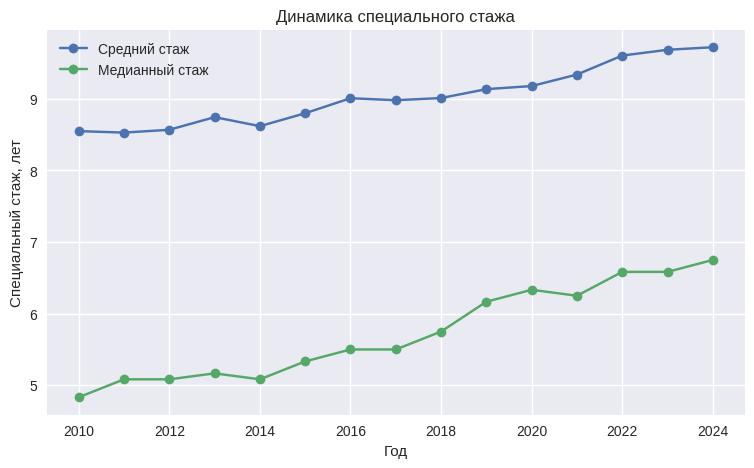

In [ ]:
tenure_dyn = (
    df_trim
    .groupby("year")
    .agg(
        n=("person_id", "count"),
        tenure_mean=("tenure", "mean"),
        tenure_median=("tenure", "median"),
        tenure_p25=("tenure", lambda x: x.quantile(0.25)),
        tenure_p75=("tenure", lambda x: x.quantile(0.75)),
        share_tenure_lt1=("tenure", lambda x: (x < 1).mean()),
        share_tenure_1_2=("tenure", lambda x: ((x >= 1) & (x < 2)).mean()),
        share_tenure_2_5=("tenure", lambda x: ((x >= 2) & (x < 5)).mean()),
        share_tenure_5_10=("tenure", lambda x: ((x >= 5) & (x < 10)).mean()),
        share_tenure_10plus=("tenure", lambda x: (x >= 10).mean()),
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.plot(tenure_dyn["year"], tenure_dyn["tenure_mean"], marker="o", label="Средний стаж")
plt.plot(tenure_dyn["year"], tenure_dyn["tenure_median"], marker="o", label="Медианный стаж")
plt.xlabel("Год")
plt.ylabel("Специальный стаж, лет")
plt.title("Динамика специального стажа")
plt.legend()
plt.grid(True)
plt.show()

Структура по группам стажа

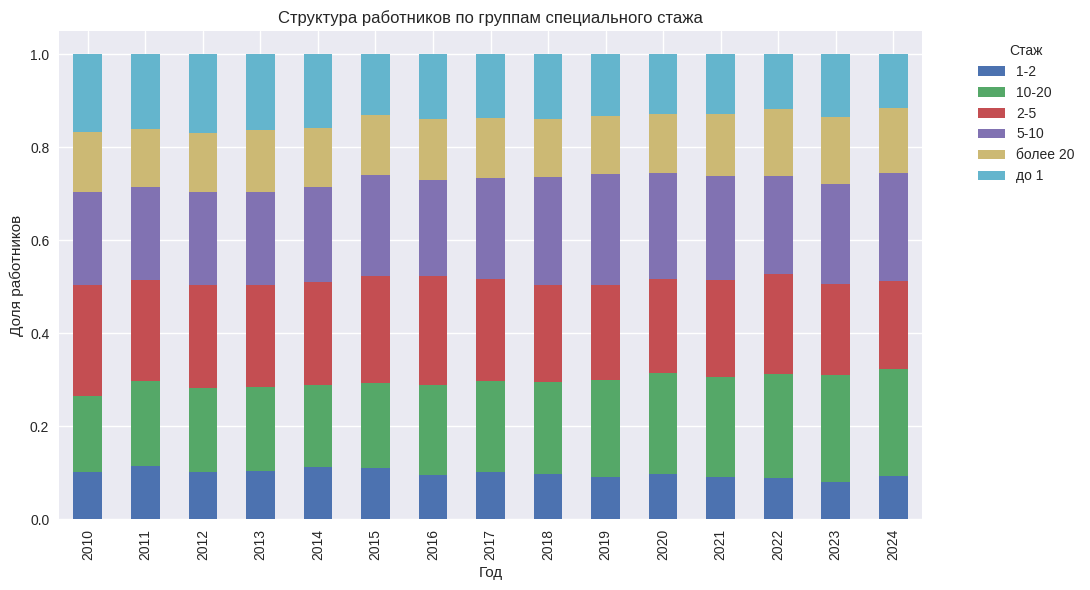

In [ ]:
tenure_structure = (
    df_trim
    .dropna(subset=["tenure_cat"])
    .groupby(["year", "tenure_cat"], observed=True)
    .size()
    .reset_index(name="n")
)

tenure_structure["share"] = (
    tenure_structure["n"] /
    tenure_structure.groupby("year")["n"].transform("sum")
)

tenure_structure_pivot = tenure_structure.pivot(
    index="year",
    columns="tenure_cat",
    values="share"
)

tenure_structure_pivot.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.xlabel("Год")
plt.ylabel("Доля работников")
plt.title("Структура работников по группам специального стажа")
plt.legend(title="Стаж",bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Динамика мобильности

<Figure size 800x550 with 0 Axes>

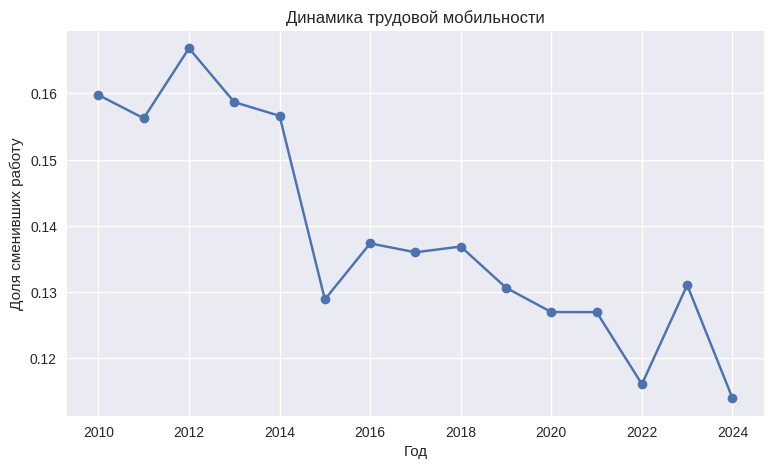

In [ ]:
mobility_dyn = (
    df_trim
    .groupby("year")
    .agg(
        n=("mobility", "count"),
        mobility_share=("mobility", "mean")
    )
    .reset_index()
)
plt.tight_layout()
plt.figure(figsize=(9, 5))
plt.plot(mobility_dyn["year"], mobility_dyn["mobility_share"], marker="o")
plt.xlabel("Год")
plt.ylabel("Доля сменивших работу")
plt.title("Динамика трудовой мобильности")
plt.grid(True)
plt.show()

Динамика зарплат

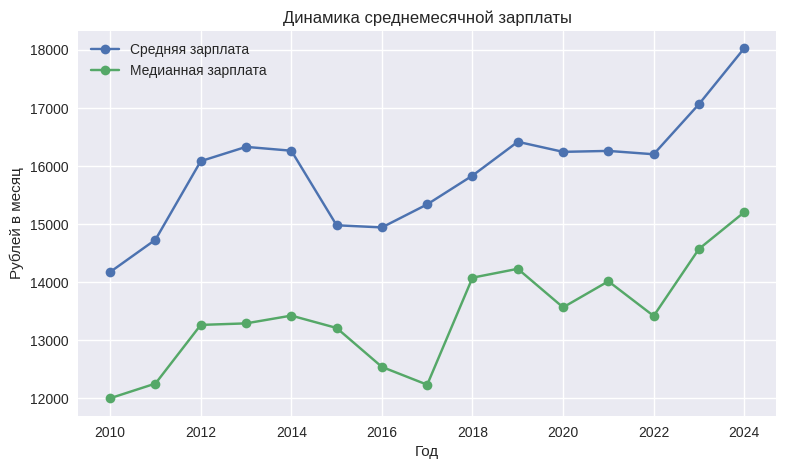

In [ ]:
wage_dyn = (
    df_trim
    .groupby("year")
    .agg(
        n=("person_id", "count"),
        wage_mean=("wage_month", "mean"),
        wage_median=("wage_month", "median"),
        ln_wage_mean=("ln_wage", "mean"),
        ln_wage_median=("ln_wage", "median")
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.plot(wage_dyn["year"], wage_dyn["wage_mean"], marker="o", label="Средняя зарплата")
plt.plot(wage_dyn["year"], wage_dyn["wage_median"], marker="o", label="Медианная зарплата")
plt.xlabel("Год")
plt.ylabel("Рублей в месяц")
plt.title("Динамика среднемесячной зарплаты")
plt.legend()
plt.grid(True)
plt.show()

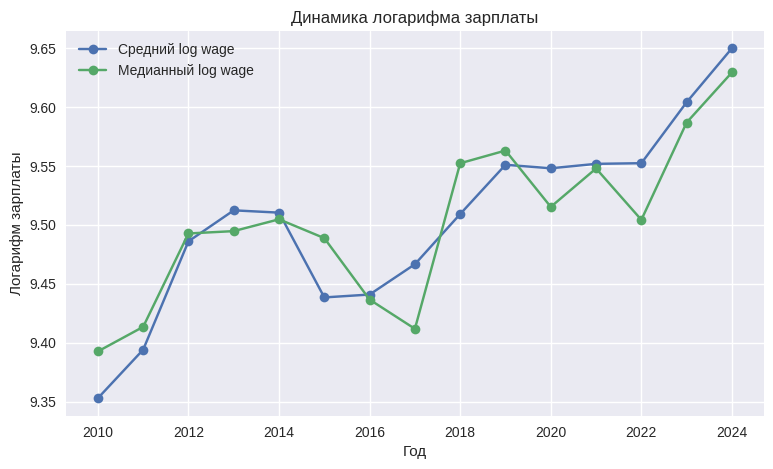

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(wage_dyn["year"], wage_dyn["ln_wage_mean"], marker="o", label="Средний log wage")
plt.plot(wage_dyn["year"], wage_dyn["ln_wage_median"], marker="o", label="Медианный log wage")
plt.xlabel("Год")
plt.ylabel("Логарифм зарплаты")
plt.title("Динамика логарифма зарплаты")
plt.legend()
plt.grid(True)
plt.show()

Зарплата по группам стажа

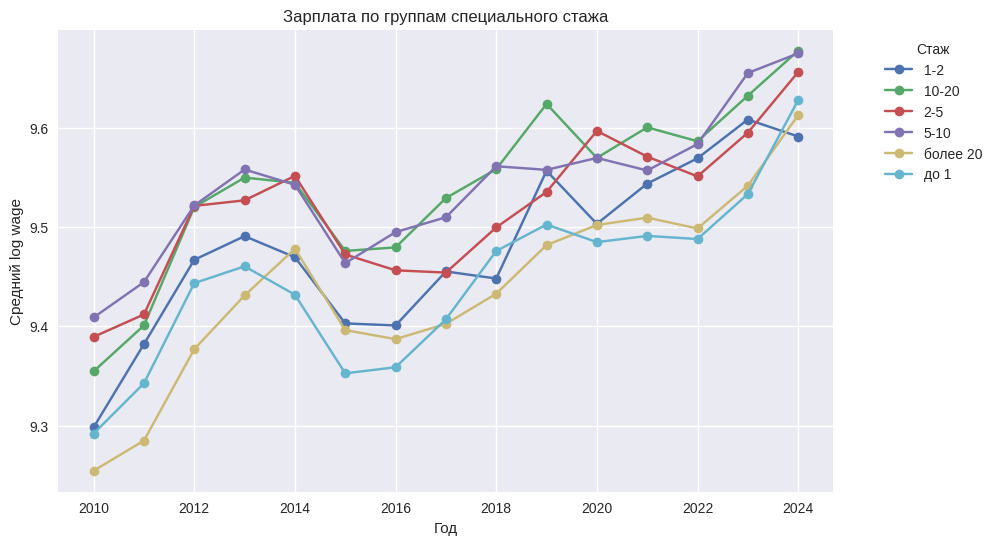

In [ ]:
wage_by_tenure = (
    df_trim
    .dropna(subset=["tenure_cat"])
    .groupby(["year", "tenure_cat"], observed=True)
    .agg(
        wage_median=("wage_month", "median"),
        ln_wage_mean=("ln_wage", "mean"),
        n=("person_id", "count")
    )
    .reset_index()
)

wage_by_tenure_pivot = wage_by_tenure.pivot(
    index="year",
    columns="tenure_cat",
    values="ln_wage_mean"
)

wage_by_tenure_pivot.plot(figsize=(10, 6), marker="o")
plt.xlabel("Год")
plt.ylabel("Средний log wage")
plt.title("Зарплата по группам специального стажа")
plt.legend(title="Стаж",bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

Структура по полу

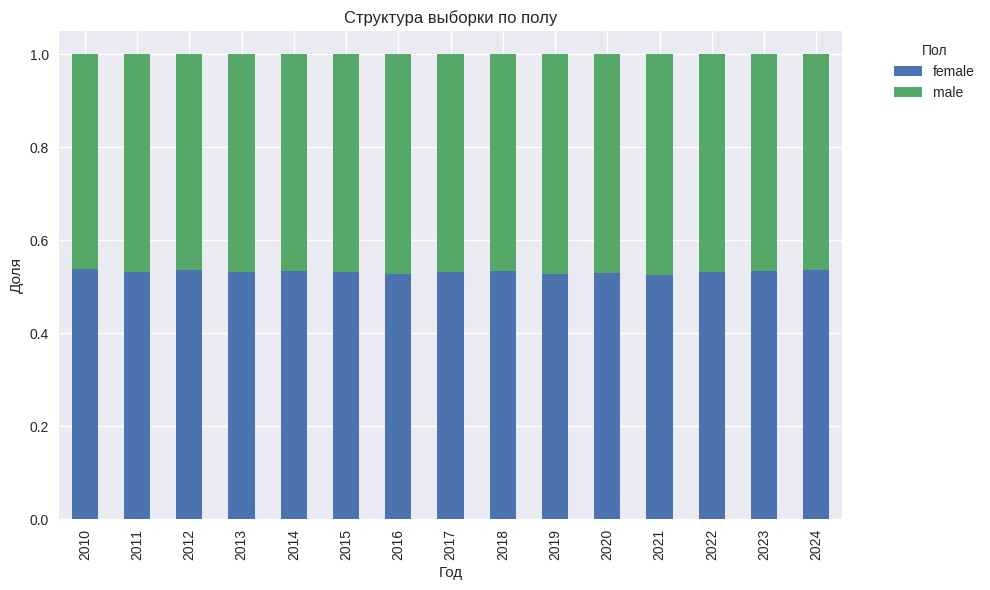

In [ ]:
gender_structure = (
    df_trim
    .groupby(["year", "sex"])
    .size()
    .reset_index(name="n")
)

# Переводим в подписи
gender_structure["sex_label"] = gender_structure["sex"].map({
    1: "male",
    2: "female"
})

# Доли внутри года
gender_structure["share"] = (
    gender_structure["n"] /
    gender_structure.groupby("year")["n"].transform("sum")
)

# Pivot
gender_pivot = gender_structure.pivot(
    index="year",
    columns="sex_label",
    values="share"
)

gender_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Год")
plt.ylabel("Доля")
plt.title("Структура выборки по полу")
plt.legend(title="Пол", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Структура по образованию

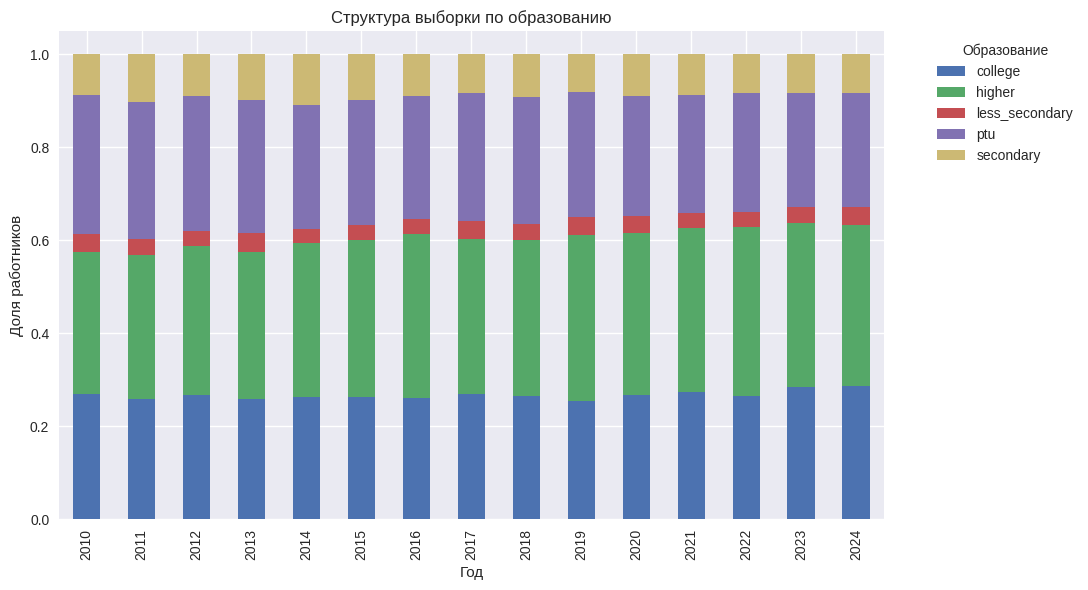

In [ ]:
educ_structure = (
    df_trim
    .dropna(subset=["educ_cat"])
    .groupby(["year", "educ_cat"], observed=True)
    .size()
    .reset_index(name="n")
)

educ_structure["share"] = (
    educ_structure["n"] /
    educ_structure.groupby("year")["n"].transform("sum")
)

educ_structure_pivot = educ_structure.pivot(
    index="year",
    columns="educ_cat",
    values="share"
)

educ_structure_pivot.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.xlabel("Год")
plt.ylabel("Доля работников")
plt.title("Структура выборки по образованию")
plt.legend(title="Образование",bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Структура по размеру фирмы

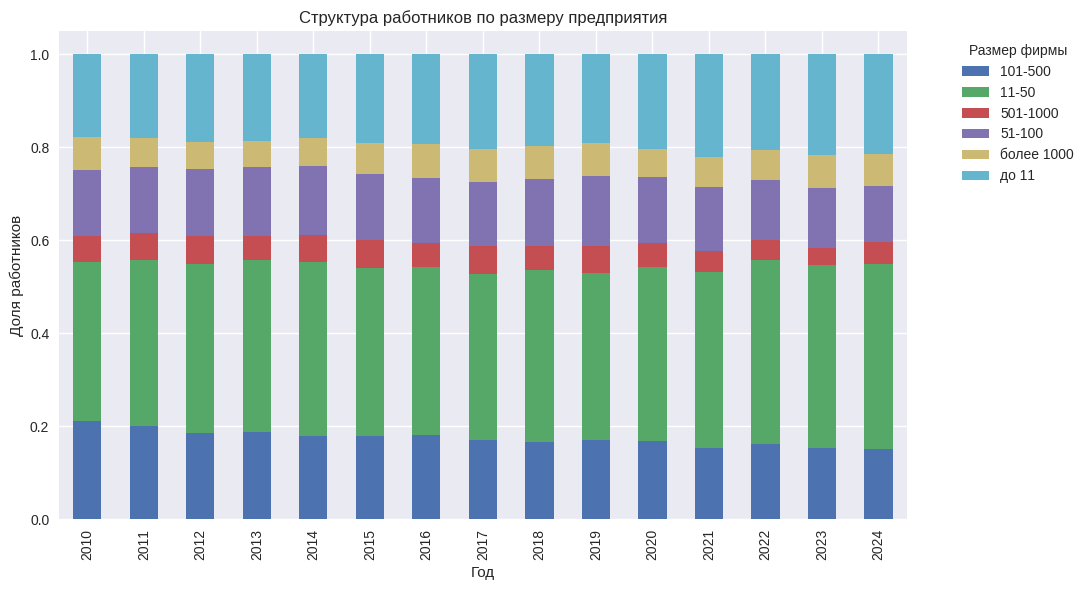

In [ ]:
firm_structure = (
    df_trim
    .dropna(subset=["firm_size_cat"])
    .groupby(["year", "firm_size_cat"], observed=True)
    .size()
    .reset_index(name="n")
)

firm_structure["share"] = (
    firm_structure["n"] /
    firm_structure.groupby("year")["n"].transform("sum")
)

firm_structure_pivot = firm_structure.pivot(
    index="year",
    columns="firm_size_cat",
    values="share"
)

firm_structure_pivot.plot(kind="bar", stacked=True, figsize=(11, 6))
plt.xlabel("Год")
plt.ylabel("Доля работников")
plt.title("Структура работников по размеру предприятия")
plt.legend(title="Размер фирмы",bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Модели

Удалено наблюдений: 653
Доля удалённых: 0.009068814665648219


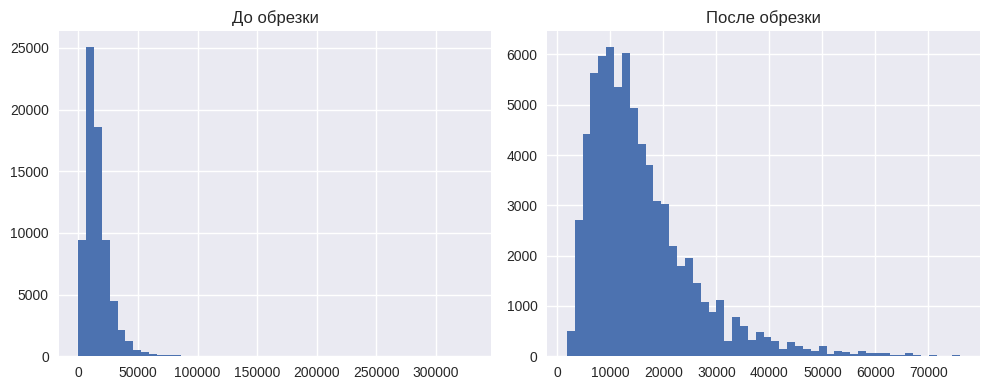

In [ ]:
def trim_wage_by_year(df, col="wage_month", q_low=0.005, q_high=0.995):
    df = df.copy()

    # считаем пороги по каждому году
    low = df.groupby("year")[col].transform(lambda x: x.quantile(q_low))
    high = df.groupby("year")[col].transform(lambda x: x.quantile(q_high))

    # оставляем только внутри интервала
    df = df[(df[col] >= low) & (df[col] <= high)]

    return df

df_trim = df.copy()
df_trim = df_trim[df_trim["wage_month"] > 0]
df_trim = trim_by_year(df_trim, "wage_month")

# Проверка
before = df.shape[0]
after = df_trim.shape[0]

print("Удалено наблюдений:", before - after)
print("Доля удалённых:", (before - after) / before)



plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df["wage_month"].dropna(), bins=50)
plt.title("До обрезки")

plt.subplot(1, 2, 2)
plt.hist(df_trim["wage_month"].dropna(), bins=50)
plt.title("После обрезки")

plt.tight_layout()
plt.show()

### Базовая pooled OLS

In [ ]:
ols_df = df_trim[
    df_trim["ln_wage"].notna()
    & df_trim["tenure"].notna()
    & df_trim["experience"].notna()
    & df_trim["ln_hours"].notna()
    & df_trim["educ_cat"].notna()
    & df_trim["male"].notna()
].copy()

ols_df["tenure2"] = ols_df["tenure"] ** 2
ols_df["experience2"] = ols_df["experience"] ** 2

In [ ]:
formula_1 = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + C(year)
"""

model_1 = smf.ols(formula_1, data=ols_df).fit(
    cov_type="cluster",
    cov_kwds={"groups": ols_df["person_id"]}
)

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.238
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     193.9
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:25   Log-Likelihood:                -43357.
No. Observations:               57453   AIC:                         8.676e+04
Df Residuals:                   57428   BIC:                         8.699e+04
Df Model:                          24                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

In [ ]:
from statsmodels.iolib.summary2 import summary_col
table = summary_col(
    [model_1],
    stars=True,
    float_format='%0.4f',
    model_names=['OLS'],
    info_dict={
        'N': lambda x: f"{int(x.nobs)}",
        'R2': lambda x: f"{x.rsquared:.3f}"
    }
)

print(table)


                                                                   OLS    
--------------------------------------------------------------------------
Intercept                                                       7.3415*** 
                                                                (0.0643)  
C(educ_cat, Treatment(reference="less_secondary"))[T.college]   0.1928*** 
                                                                (0.0249)  
C(educ_cat, Treatment(reference="less_secondary"))[T.higher]    0.5176*** 
                                                                (0.0249)  
C(educ_cat, Treatment(reference="less_secondary"))[T.ptu]       0.0975*** 
                                                                (0.0246)  
C(educ_cat, Treatment(reference="less_secondary"))[T.secondary] 0.1416*** 
                                                                (0.0267)  
C(year)[T.2011]                                                 0.0555*** 
                        

In [ ]:
ols_df2 = ols_df[
    ols_df["state_owned"].notna()
    & ols_df["firm_size_cat"].notna()
].copy()

formula_2 = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
"""

model_2 = smf.ols(formula_2, data=ols_df2).fit(
    cov_type="cluster",
    cov_kwds={"groups": ols_df2["person_id"]}
)

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     165.1
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:26   Log-Likelihood:                -29862.
No. Observations:               41617   AIC:                         5.979e+04
Df Residuals:                   41586   BIC:                         6.005e+04
Df Model:                          30                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

In [ ]:
def tenure_premium(model, years):
    b1 = model.params["tenure"]
    b2 = model.params["tenure2"]

    log_premium = b1 * years + b2 * years**2
    percent_premium = 100 * (np.exp(log_premium) - 1)

    return log_premium, percent_premium

for s in [1, 2, 5, 10, 15, 20]:
    lp, pp = tenure_premium(model_2, s)
    print(f"{s:>2} лет стажа: log premium = {lp:.4f}, premium = {pp:.2f}%")

premium_table = pd.DataFrame({
    "tenure_years": [1, 2, 5, 10, 15, 20]
})

premium_table["log_premium"] = premium_table["tenure_years"].apply(
    lambda s: tenure_premium(model_2, s)[0]
)

premium_table["premium_percent"] = premium_table["tenure_years"].apply(
    lambda s: tenure_premium(model_2, s)[1]
)

premium_table

 1 лет стажа: log premium = 0.0046, premium = 0.46%
 2 лет стажа: log premium = 0.0091, premium = 0.92%
 5 лет стажа: log premium = 0.0220, premium = 2.22%
10 лет стажа: log premium = 0.0413, premium = 4.22%
15 лет стажа: log premium = 0.0580, premium = 5.97%
20 лет стажа: log premium = 0.0721, premium = 7.47%


,tenure_years,log_premium,premium_percent
0,1,0.004608,0.461874
1,2,0.009110,0.915200
2,5,0.021982,2.222546
3,10,0.041318,4.218345
4,15,0.058008,5.972319
5,20,0.072051,7.471048


### OLS по отдельным годам

In [ ]:
def stars(p):
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def coef_with_se(model, var):
    coef = model.params.get(var, np.nan)
    se = model.bse.get(var, np.nan)
    p = model.pvalues.get(var, np.nan)

    if pd.isna(coef):
        return ""

    return f"{coef:.4f}{stars(p)}"

In [ ]:
formula_year = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
"""

models_by_year = {}
rows = []

for year in range(2010, 2025):
    df_y = df_trim[
        (df_trim["year"] == year)
        & df_trim["ln_wage"].notna()
        & df_trim["tenure"].notna()
        & df_trim["experience"].notna()
        & df_trim["ln_hours"].notna()
        & df_trim["educ_cat"].notna()
        & df_trim["male"].notna()
    ].copy()

    df_y["tenure2"] = df_y["tenure"] ** 2
    df_y["experience2"] = df_y["experience"] ** 2

    model_y = smf.ols(formula_year, data=df_y).fit(cov_type="HC1")
    models_by_year[year] = model_y

variables = {
    "tenure": "Специальный стаж",
    "tenure2": "Специальный стаж²",
    "experience": "Общий трудовой стаж",
    "experience2": "Общий трудовой стаж²",
    "ln_hours": "Лог рабочих часов",
    "male": "Мужчина",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.secondary]': "Среднее образование",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.ptu]': "ПТУ",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.college]': "Техникум / колледж",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.higher]': "Высшее образование",
    "Intercept": "Константа",
}

table = pd.DataFrame(index=variables.values())

for year, model in models_by_year.items():
    table[str(year)] = [
        coef_with_se(model, var)
        for var in variables.keys()
    ]

# добавим N и R2
table.loc["N"] = [f"{int(models_by_year[y].nobs)}" for y in models_by_year]
table.loc["R²"] = [f"{models_by_year[y].rsquared:.3f}" for y in models_by_year]

table

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Специальный стаж,0.0073***,0.0035,0.0055**,0.0113***,0.0092***,0.0059**,0.0037,0.0065**,0.0037,0.0069***,0.0040,0.0008,-0.0010,-0.0010,-0.0020
Специальный стаж²,-0.0001*,-0.0000,-0.0001,-0.0002***,-0.0001,0.0000,0.0000,-0.0000,0.0000,-0.0001,0.0000,0.0001,0.0001,0.0001,0.0001*
Общий трудовой стаж,-0.0032,0.0028,0.0042,0.0072***,0.0093***,0.0111***,0.0131***,0.0108***,0.0160***,0.0129***,0.0107***,0.0125***,0.0123***,0.0107***,0.0106***
Общий трудовой стаж²,-0.0001,-0.0002***,-0.0003***,-0.0003***,-0.0003***,-0.0004***,-0.0004***,-0.0004***,-0.0004***,-0.0004***,-0.0003***,-0.0004***,-0.0003***,-0.0003***,-0.0003***
Лог рабочих часов,0.5044***,0.4281***,0.4289***,0.3038***,0.4760***,0.3353***,0.4117***,0.3825***,0.4367***,0.4370***,0.4082***,0.3977***,0.3978***,0.4077***,0.3654***
Мужчина,0.3279***,0.3660***,0.3363***,0.3491***,0.3110***,0.3428***,0.3219***,0.3309***,0.2950***,0.2876***,0.2926***,0.2717***,0.2693***,0.2949***,0.3047***
Среднее образование,0.2263***,0.1312**,0.1151,0.1749***,0.1336**,0.1396**,0.2077***,0.1829***,0.1729***,0.1340**,0.0141,0.1252**,0.1376***,0.0597,0.2299***
ПТУ,0.1977***,0.1341**,0.0943,0.1300***,0.1156**,0.1005*,0.1836***,0.0944*,0.1546***,0.0742,-0.0767,0.0655,0.1076***,0.0090,0.0969**
Техникум / колледж,0.3317***,0.2688***,0.1960***,0.2366***,0.2308***,0.1905***,0.2570***,0.1921***,0.2335***,0.1495***,0.0365,0.1465***,0.1634***,0.0979**,0.1861***
Высшее образование,0.6623***,0.6115***,0.5273***,0.5703***,0.5712***,0.5451***,0.6072***,0.5231***,0.5552***,0.4681***,0.3321***,0.4580***,0.4691***,0.3781***,0.4929***


In [ ]:
formula_year = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
"""

models_by_year = {}

for year in range(2010, 2025):
    df_y = df_trim[
        (df_trim["year"] == year)
        & df_trim["ln_wage"].notna()
        & df_trim["tenure"].notna()
        & df_trim["experience"].notna()
        & df_trim["ln_hours"].notna()
        & df_trim["educ_cat"].notna()
        & df_trim["male"].notna()
        & df_trim["state_owned"].notna()
        & df_trim["firm_size_cat"].notna()
    ].copy()

    df_y["tenure2"] = df_y["tenure"] ** 2
    df_y["experience2"] = df_y["experience"] ** 2

    model_y = smf.ols(formula_year, data=df_y).fit(cov_type="HC1")
    models_by_year[year] = model_y


variables = {
    "tenure": "Специальный стаж",
    "tenure2": "Специальный стаж²",
    "experience": "Общий трудовой стаж",
    "experience2": "Общий трудовой стаж²",
    "ln_hours": "Лог рабочих часов",
    "male": "Мужчина",

    'C(educ_cat, Treatment(reference="less_secondary"))[T.secondary]': "Среднее образование",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.ptu]': "ПТУ",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.college]': "Техникум / колледж",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.higher]': "Высшее образование",

    "state_owned": "Государственное предприятие",

    'C(firm_size_cat, Treatment(reference="до 11"))[T.11-50]': "Размер фирмы: 11–50",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.51-100]': "Размер фирмы: 51–100",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.101-500]': "Размер фирмы: 101–500",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.501-1000]': "Размер фирмы: 501–1000",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.более 1000]': "Размер фирмы: более 1000",

    "Intercept": "Константа",
}


table = pd.DataFrame(index=variables.values())

for year, model in models_by_year.items():
    table[str(year)] = [
        coef_with_se(model, var)
        for var in variables.keys()
    ]

table.loc["N"] = [f"{int(models_by_year[y].nobs)}" for y in models_by_year]
table.loc["R²"] = [f"{models_by_year[y].rsquared:.3f}" for y in models_by_year]

table

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Специальный стаж,0.0116***,0.0072**,0.0053,0.0139***,0.0105***,0.0045,0.0001,0.0083***,0.0050*,0.0080***,0.0039,-0.0009,-0.0048*,-0.0005,-0.0006
Специальный стаж²,-0.0003***,-0.0002**,-0.0001,-0.0003***,-0.0002**,0.0000,0.0001,-0.0001,-0.0000,-0.0001*,-0.0000,0.0001,0.0001*,0.0001,0.0000
Общий трудовой стаж,-0.0019,0.0057,0.0064,0.0098***,0.0103***,0.0135***,0.0147***,0.0102***,0.0171***,0.0139***,0.0100***,0.0107***,0.0126***,0.0108***,0.0105***
Общий трудовой стаж²,-0.0001,-0.0002***,-0.0003***,-0.0003***,-0.0003***,-0.0004***,-0.0004***,-0.0003***,-0.0005***,-0.0004***,-0.0003***,-0.0003***,-0.0003***,-0.0003***,-0.0003***
Лог рабочих часов,0.4178***,0.3310***,0.3388***,0.2117***,0.4118***,0.3075***,0.3716***,0.2978***,0.3873***,0.3958***,0.3707***,0.3816***,0.3639***,0.3878***,0.2958***
Мужчина,0.2650***,0.2868***,0.2864***,0.2906***,0.2652***,0.2715***,0.2644***,0.2793***,0.2525***,0.2502***,0.2459***,0.2491***,0.2382***,0.2504***,0.2738***
Среднее образование,0.1413*,0.1114,0.1090,0.1468**,0.1206,0.1453**,0.1973***,0.1727***,0.1574**,0.1559**,0.0159,0.1596***,0.1371**,0.0538,0.1739***
ПТУ,0.1157,0.0792,0.0833,0.0853,0.1085,0.1065*,0.1588***,0.0796,0.1314**,0.0565,-0.0711,0.0896,0.1000**,0.0339,0.1099*
Техникум / колледж,0.2665***,0.2404***,0.2173***,0.2113***,0.2245***,0.2191***,0.2600***,0.1723***,0.2335***,0.1555***,0.0650,0.1742***,0.1345***,0.1142**,0.1579***
Высшее образование,0.5983***,0.5931***,0.5516***,0.5419***,0.5794***,0.5844***,0.6173***,0.5019***,0.5509***,0.4517***,0.3617***,0.4856***,0.4441***,0.4024***,0.4525***


In [ ]:
formula_year = """
ln_wage ~ experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(tenure_cat, Treatment(reference="до 1"))
"""

models_by_year_cat = {}

for year in range(2010, 2025):
    df_y = df_trim[
        (df_trim["year"] == year)
        & df_trim["ln_wage"].notna()
        & df_trim["tenure_cat"].notna()
        & df_trim["experience"].notna()
        & df_trim["ln_hours"].notna()
        & df_trim["educ_cat"].notna()
        & df_trim["male"].notna()
        & df_trim["state_owned"].notna()
        & df_trim["firm_size_cat"].notna()
    ].copy()

    df_y["experience2"] = df_y["experience"] ** 2

    if len(df_y) < 100:
        continue

    model_y = smf.ols(formula_year, data=df_y).fit(cov_type="HC1")
    models_by_year_cat[year] = model_y


variables_cat = {
    'C(tenure_cat, Treatment(reference="до 1"))[T.1-2]': "Стаж 1–2 года",
    'C(tenure_cat, Treatment(reference="до 1"))[T.2-5]': "Стаж 2–5 лет",
    'C(tenure_cat, Treatment(reference="до 1"))[T.5-10]': "Стаж 5–10 лет",
    'C(tenure_cat, Treatment(reference="до 1"))[T.10-20]': "Стаж 10–20 лет",
    'C(tenure_cat, Treatment(reference="до 1"))[T.более 20]': "Стаж более 20 лет",

    "experience": "Общий трудовой стаж",
    "experience2": "Общий трудовой стаж²",
    "ln_hours": "Лог рабочих часов",
    "male": "Мужчина",

    'C(educ_cat, Treatment(reference="less_secondary"))[T.secondary]': "Среднее образование",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.ptu]': "ПТУ",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.college]': "Техникум / колледж",
    'C(educ_cat, Treatment(reference="less_secondary"))[T.higher]': "Высшее образование",

    "state_owned": "Государственное предприятие",

    'C(firm_size_cat, Treatment(reference="до 11"))[T.11-50]': "Размер фирмы: 11–50",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.51-100]': "Размер фирмы: 51–100",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.101-500]': "Размер фирмы: 101–500",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.501-1000]': "Размер фирмы: 501–1000",
    'C(firm_size_cat, Treatment(reference="до 11"))[T.более 1000]': "Размер фирмы: более 1000",

    "Intercept": "Константа",
}


table_cat = pd.DataFrame(index=variables_cat.values())

for year, model in models_by_year_cat.items():
    table_cat[str(year)] = [
        coef_with_se(model, var)
        for var in variables_cat.keys()
    ]

table_cat.loc["N"] = [f"{int(models_by_year_cat[y].nobs)}" for y in models_by_year_cat]
table_cat.loc["R²"] = [f"{models_by_year_cat[y].rsquared:.3f}" for y in models_by_year_cat]

table_cat


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Стаж 1–2 года,-0.0287,-0.0022,-0.0449,0.0493,0.0202,0.0631,-0.0127,0.0528,-0.0964**,-0.0076,0.0291,-0.0109,0.0623,0.0255,-0.0520
Стаж 2–5 лет,0.0825*,0.0306,0.0145,0.0553*,0.1214***,0.0781**,0.0403,0.0668*,-0.0058,0.0097,0.0353,0.0141,-0.0202,0.0241,-0.0163
Стаж 5–10 лет,0.0954**,0.0495,0.0578,0.1064***,0.1133***,0.1031***,0.0517,0.1285***,0.0434,0.0410,0.0495,-0.0107,0.0056,0.0615*,0.0092
Стаж 10–20 лет,0.1242***,0.0723*,0.0722*,0.1660***,0.1654***,0.1223***,0.0517,0.1589***,0.0637*,0.0994***,0.0679*,0.0289,0.0029,0.0548,0.0016
Стаж более 20 лет,0.0724,0.0479,0.0533,0.1457***,0.1851***,0.1714***,0.1007**,0.1695***,0.0701*,0.0653*,0.0957**,0.0477,-0.0159,0.0547,-0.0025
Общий трудовой стаж,0.0008,0.0073*,0.0071,0.0104***,0.0100***,0.0120***,0.0130***,0.0092***,0.0160***,0.0140***,0.0098***,0.0097***,0.0114***,0.0092***,0.0094***
Общий трудовой стаж²,-0.0001,-0.0003***,-0.0003***,-0.0004***,-0.0003***,-0.0004***,-0.0004***,-0.0003***,-0.0004***,-0.0004***,-0.0003***,-0.0003***,-0.0003***,-0.0002***,-0.0003***
Лог рабочих часов,0.4172***,0.3322***,0.3403***,0.2123***,0.4127***,0.3068***,0.3719***,0.2958***,0.3890***,0.3942***,0.3710***,0.3817***,0.3663***,0.3853***,0.2972***
Мужчина,0.2611***,0.2862***,0.2867***,0.2904***,0.2629***,0.2687***,0.2617***,0.2755***,0.2493***,0.2492***,0.2449***,0.2483***,0.2368***,0.2474***,0.2730***
Среднее образование,0.1302,0.1094,0.1069,0.1411**,0.1217*,0.1458**,0.1998***,0.1745***,0.1648**,0.1573**,0.0162,0.1580***,0.1442***,0.0543,0.1708***


### Модель с шоками

In [ ]:
shock_df = df_trim[
    df_trim["ln_wage"].notna()
    & df_trim["tenure"].notna()
    & df_trim["experience"].notna()
    & df_trim["ln_hours"].notna()
    & df_trim["educ_cat"].notna()
    & df_trim["male"].notna()
    & df_trim["state_owned"].notna()
    & df_trim["firm_size_cat"].notna()
].copy()

shock_df["tenure2"] = shock_df["tenure"] ** 2
shock_df["experience2"] = shock_df["experience"] ** 2

shock_df["post2020"] = (shock_df["year"] >= 2020).astype(int)
shock_df["post2022"] = (shock_df["year"] >= 2022).astype(int)

In [ ]:
formula_shock = """
ln_wage ~ tenure + tenure2
        + tenure:post2020 + tenure2:post2020
        + tenure:post2022 + tenure2:post2022
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
"""

model_shock = smf.ols(formula_shock, data=shock_df).fit(
    cov_type="cluster",
    cov_kwds={"groups": shock_df["person_id"]}
)

print(model_shock.summary())

def shock_premium(model, s, post2020=0, post2022=0):
    b_tenure = model.params.get("tenure", 0)
    b_tenure2 = model.params.get("tenure2", 0)

    b_tenure_2020 = model.params.get("tenure:post2020", 0)
    b_tenure2_2020 = model.params.get("tenure2:post2020", 0)

    b_tenure_2022 = model.params.get("tenure:post2022", 0)
    b_tenure2_2022 = model.params.get("tenure2:post2022", 0)

    log_premium = (
        (b_tenure + post2020 * b_tenure_2020 + post2022 * b_tenure_2022) * s
        + (b_tenure2 + post2020 * b_tenure2_2020 + post2022 * b_tenure2_2022) * s**2
    )

    return 100 * (np.exp(log_premium) - 1)

shock_premiums = []

for s in [1, 2, 5, 10, 15, 20]:
    shock_premiums.append({
        "tenure_years": s,
        "pre_2020": shock_premium(model_shock, s, post2020=0, post2022=0),
        "post_2020": shock_premium(model_shock, s, post2020=1, post2022=0),
        "post_2022": shock_premium(model_shock, s, post2020=1, post2022=1),
    })

shock_premiums = pd.DataFrame(shock_premiums)
shock_premiums

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     146.9
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:32   Log-Likelihood:                -29848.
No. Observations:               41617   AIC:                         5.977e+04
Df Residuals:                   41582   BIC:                         6.007e+04
Df Model:                          34                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

,tenure_years,pre_2020,post_2020,post_2022
0,1,0.674665,0.202806,-0.124921
1,2,1.330013,0.415708,-0.226082
2,5,3.175857,1.115637,-0.387643
3,10,5.827603,2.490574,-0.185130
4,15,7.910232,4.135022,0.611145
5,20,9.387849,6.061311,2.015404


### FE

In [ ]:
fe_df = df_trim[
    df_trim["person_id"].notna()
    & df_trim["year"].notna()
    & df_trim["ln_wage"].notna()
    & df_trim["tenure"].notna()
    & df_trim["experience"].notna()
    & df_trim["ln_hours"].notna()
    & df_trim["state_owned"].notna()
    & df_trim["firm_size_cat"].notna()
    & df_trim["educ_cat"].notna()
].copy()

fe_df["tenure2"] = fe_df["tenure"] ** 2
fe_df["experience2"] = fe_df["experience"] ** 2

fe_df = fe_df.set_index(["person_id", "year"])


fe_formula = """
ln_wage ~ 1
        + tenure + tenure2
        + experience + experience2
        + ln_hours
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + EntityEffects
        + TimeEffects
"""

fe_model = PanelOLS.from_formula(
    fe_formula,
    data=fe_df,
    drop_absorbed=True
)

fe_res = fe_model.fit(
    cov_type="clustered",
    cluster_entity=True
)

print(fe_res)

                          PanelOLS Estimation Summary                           
Dep. Variable:                ln_wage   R-squared:                        0.0442
Estimator:                   PanelOLS   R-squared (Between):              0.0347
No. Observations:               41610   R-squared (Within):               0.0505
Date:                Sat, May 09 2026   R-squared (Overall):              0.0404
Time:                        23:06:32   Log-likelihood                    7401.1
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      125.19
Entities:                       11784   P-value                           0.0000
Avg Obs:                       3.5311   Distribution:                F(11,29801)
Min Obs:                       1.0000                                           
Max Obs:                       15.000   F-statistic (robust):             29.920
                            

### Altonji–Shakotko (IV)

In [ ]:
iv_df = df_trim[
    df_trim["person_id"].notna()
    & df_trim["ln_wage"].notna()
    & df_trim["tenure"].notna()
    & df_trim["experience"].notna()
    & df_trim["ln_hours"].notna()
    & df_trim["educ_cat"].notna()
    & df_trim["male"].notna()
    & df_trim["state_owned"].notna()
    & df_trim["firm_size_cat"].notna()
].copy()


iv_df["tenure2"] = iv_df["tenure"] ** 2
iv_df["experience2"] = iv_df["experience"] ** 2

# инструменты
iv_df["tenure_mean_i"] = iv_df.groupby("person_id")["tenure"].transform("mean")
iv_df["tenure_as"] = iv_df["tenure"] - iv_df["tenure_mean_i"]
iv_df["tenure_as2"] = iv_df["tenure_as"] ** 2

In [ ]:
iv_formula = """
ln_wage ~ 1
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
        + [tenure + tenure2 ~ tenure_as + tenure_as2]
"""

iv_model = IV2SLS.from_formula(iv_formula, data=iv_df)

iv_res = iv_model.fit(
    cov_type="clustered",
    clusters=iv_df["person_id"]
)

print(iv_res.summary)

                          IV-2SLS Estimation Summary                          
Dep. Variable:                ln_wage   R-squared:                      0.2916
Estimator:                    IV-2SLS   Adj. R-squared:                 0.2911
No. Observations:               41610   F-statistic:                    4912.9
Date:                Sat, May 09 2026   P-value (F-stat)                0.0000
Time:                        23:06:33   Distribution:                 chi2(30)
Cov. Estimator:             clustered                                         
                                                                              
                                                        Parameter Estimates                                                        
                                                                 Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
--------------------------------------------------------------------------------------------------------

In [ ]:
iv_res.first_stage.summary

,tenure,tenure2
R-squared,0.3994,0.3356
Partial R-squared,0.1750,0.1214
Shea's R-squared,0.0126,0.0088
Partial F-statistic,1.236e+04,2643.3
P-value (Partial F-stat),0.0000,0.0000
Partial F-stat Distn,chi2(2),chi2(2)
=================================================================,===========,===========
Intercept,2.2494,45.517
,(1.9736),(1.0762)
experience,0.3441,0.0968


## Исправление ошибок измерения специального стажа по Ощепкову

In [ ]:
ols_df = df_trim[
    df_trim["ln_wage"].notna()
    & df_trim["tenure"].notna()
    & df_trim["experience"].notna()
    & df_trim["ln_hours"].notna()
    & df_trim["educ_cat"].notna()
    & df_trim["male"].notna()
    & df_trim["state_owned"].notna()
    & df_trim["firm_size_cat"].notna()
].copy()

ols_df["tenure2"] = ols_df["tenure"] ** 2
ols_df["experience2"] = ols_df["experience"] ** 2

### Строгая выборка (убираем, если не указан месяц)

In [ ]:
print("Было до исключения специального стажа без месяца")
print(ols_df.size)
print("Стало после исключения специального стажа без месяца")
df_strict = ols_df.dropna(subset=[ 'tenure_start_m'])
print(df_strict.size)

Было до исключения специального стажа без месяца
1456595
Стало после исключения специального стажа без месяца
1396395


In [ ]:
formula = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
"""

model = smf.ols(formula, data=df_strict).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_strict["person_id"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     159.6
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:38   Log-Likelihood:                -28471.
No. Observations:               39897   AIC:                         5.700e+04
Df Residuals:                   39866   BIC:                         5.727e+04
Df Model:                          30                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

### Панельная проверка

In [ ]:
import math

In [ ]:
df_panel_check = ols_df.sort_values(['person_id', 'year'])

df_panel_check['tenure_diff'] = df_panel_check.groupby('person_id')['tenure'].diff()
df_panel_check['year_diff'] = df_panel_check.groupby('person_id')['year'].diff()
df_panel_check['inconsistent'] = df_panel_check['tenure_diff'] - df_panel_check['year_diff'] > 0.5 #небольшая погрешность

df_panel_check[df_panel_check['inconsistent']]

,person_id,birth_year,wage_month,sex,work_hours,tenure_start_y,tenure_start_m,educ_raw,interview_m,firm_size,...,tenure_cat,educ_cat,firm_size_cat,mobility,org_worker,has_children,health_problem,tenure_diff,year_diff,inconsistent
38004,3.0,1955.0,15290.519878,2.0,48.0,2013.0,4.0,4.0,9.0,200.0,...,2-5,ptu,101-500,0,1.0,1.0,0.0,1.916667,1.0,True
18727,37.0,1956.0,14119.601329,1.0,50.0,2006.0,7.0,3.0,11.0,90.0,...,5-10,ptu,51-100,0,1.0,1.0,1.0,2.833333,2.0,True
24594,92.0,1958.0,11931.394482,2.0,37.0,1978.0,2.0,5.0,11.0,9.0,...,более 20,ptu,до 11,0,1.0,1.0,1.0,2.083333,1.0,True
29212,93.0,1954.0,17833.553501,1.0,70.0,1971.0,8.0,3.0,10.0,150.0,...,более 20,ptu,101-500,0,1.0,1.0,0.0,3.916667,1.0,True
18734,109.0,1955.0,9966.777409,1.0,48.0,1993.0,7.0,3.0,11.0,6.0,...,более 20,ptu,до 11,0,1.0,1.0,1.0,2.000000,1.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67455,63009.0,1977.0,18734.388010,2.0,36.0,2016.0,6.0,6.0,11.0,500.0,...,5-10,college,101-500,0,1.0,1.0,0.0,1.833333,1.0,True
71468,63226.0,1990.0,11402.508552,2.0,40.0,2022.0,10.0,10.0,10.0,30.0,...,2-5,higher,11-50,0,1.0,1.0,1.0,1.750000,1.0,True
71483,63295.0,1979.0,13683.010262,2.0,48.0,2016.0,6.0,1.0,11.0,40.0,...,5-10,less_secondary,11-50,0,1.0,1.0,0.0,2.083333,1.0,True
71519,63436.0,2002.0,11402.508552,1.0,94.0,2020.0,6.0,2.0,12.0,12.0,...,2-5,secondary,11-50,0,1.0,0.0,0.0,3.500000,1.0,True


In [ ]:
df_panel_check[['person_id', 'tenure_start_y', 'year', 'tenure', 'tenure_diff', 'year_diff', 'inconsistent']].head(10)

,person_id,tenure_start_y,year,tenure,tenure_diff,year_diff,inconsistent
24591,3.0,2012.0,2014,2.500000,NaN,NaN,False
29211,3.0,2013.0,2015,2.500000,0.000000,1.0,False
33679,3.0,2014.0,2016,2.500000,0.000000,1.0,False
38004,3.0,2013.0,2017,4.416667,1.916667,1.0,True
6444,37.0,2007.0,2011,4.500000,NaN,NaN,False
18727,37.0,2006.0,2013,7.333333,2.833333,2.0,True
33680,37.0,2015.0,2016,0.916667,-6.416667,3.0,False
38005,37.0,2015.0,2017,1.916667,1.000000,1.0,False
33681,39.0,2013.0,2016,3.500000,NaN,NaN,False
6,92.0,1978.0,2010,32.666667,NaN,NaN,False


In [ ]:
df_clean = df_panel_check[df_panel_check['inconsistent'] == False]

In [ ]:
formula = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
"""

model = smf.ols(formula, data=df_clean).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_clean["person_id"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.296
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     163.0
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:39   Log-Likelihood:                -27329.
No. Observations:               38285   AIC:                         5.472e+04
Df Residuals:                   38254   BIC:                         5.499e+04
Df Model:                          30                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

## Модели (продолжение)

### Топель (упрощенный)

In [ ]:
df_topel = df_clean.sort_values(['person_id', 'year']).copy()

df_topel['ln_wage'] = np.log(df_topel['wage_month'])

df_topel['d_ln_wage'] = df_topel.groupby('person_id')['ln_wage'].diff()
df_topel['d_experience'] = df_topel.groupby('person_id')['experience'].diff()
df_topel['d_tenure'] = df_topel.groupby('person_id')['tenure'].diff()

df_topel['stayer'] = df_topel['d_tenure'] > 0
df_stayers = df_topel[df_topel['stayer']]

In [ ]:
X = df_stayers[['d_tenure', 'd_experience']]
X = sm.add_constant(X)

y = df_stayers['d_ln_wage']

model_topel = sm.OLS(y, X).fit(cov_type='HC1')

print(model_topel.summary())

                            OLS Regression Results                            
Dep. Variable:              d_ln_wage   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.595
Date:                Sat, 09 May 2026   Prob (F-statistic):             0.0101
Time:                        23:06:39   Log-Likelihood:                -1535.1
No. Observations:               22624   AIC:                             3076.
Df Residuals:                   22621   BIC:                             3100.
Df Model:                           2                                         
Covariance Type:                  HC1                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0190      0.002      8.080   

### Топель (ближе к статье)

Оценка θ = γ + δ

In [ ]:
topel_step1 = smf.ols(
    formula="""
    d_ln_wage ~ d_experience + C(year)
    """,
    data=df_stayers
).fit(cov_type='cluster', cov_kwds={'groups': df_stayers['person_id']})

print(topel_step1.summary())

theta = topel_step1.params['d_experience']
print("theta = gamma + delta =", theta)

                            OLS Regression Results                            
Dep. Variable:              d_ln_wage   R-squared:                       0.025
Model:                            OLS   Adj. R-squared:                  0.024
Method:                 Least Squares   F-statistic:                     40.63
Date:                Sat, 09 May 2026   Prob (F-statistic):          1.69e-107
Time:                        23:06:39   Log-Likelihood:                -1258.9
No. Observations:               22624   AIC:                             2548.
Df Residuals:                   22609   BIC:                             2668.
Df Model:                          14                                         
Covariance Type:              cluster                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0454      0.008     

Оценка γ

In [ ]:
df_topel['experience_at_job_start'] = df_topel['experience'] - df_topel['tenure']
df_topel['ln_wage_adj'] = df_topel['ln_wage'] - theta * df_topel['tenure']
df_step2 = df_topel[
    df_topel[['ln_wage_adj', 'experience_at_job_start']].notna().all(axis=1)
].copy()

topel_step2 = smf.ols(
    formula="""
    ln_wage_adj ~ experience_at_job_start + I(experience_at_job_start**2)
    + C(educ_cat) + C(year)
    """,
    data=df_step2
).fit(cov_type='cluster', cov_kwds={'groups': df_step2['person_id']})

print(topel_step2.summary())

gamma = topel_step2.params['experience_at_job_start']
print("gamma =", gamma)

                            OLS Regression Results                            
Dep. Variable:            ln_wage_adj   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.121
Method:                 Least Squares   F-statistic:                     85.39
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:39   Log-Likelihood:                -31640.
No. Observations:               38285   AIC:                         6.332e+04
Df Residuals:                   38264   BIC:                         6.350e+04
Df Model:                          20                                         
Covariance Type:              cluster                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [ ]:
delta = theta - gamma

print("Topel estimate of tenure return:")
print("delta =", delta)
print("percent effect ≈", 100 * delta, "% за 1 год специального стажа")

Topel estimate of tenure return:
delta = -0.010109190119583234
percent effect ≈ -1.0109190119583233 % за 1 год специального стажа


### Year-specific tenure returns

In [ ]:
df_event = ols_df.copy()

df_event['tenure2'] = df_event['tenure'] ** 2

event_model = smf.ols(
    formula="""
    ln_wage ~ C(year)
    + tenure:C(year)
    + tenure2:C(year)
    + experience + experience2
    + male
    + C(educ_cat, Treatment(reference="less_secondary"))
    + state_owned
    + C(firm_size_cat, Treatment(reference="до 11"))
    """,
    data=df_event
).fit(cov_type='cluster', cov_kwds={'groups': df_event['person_id']})


print(event_model.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.276
Model:                            OLS   Adj. R-squared:                  0.275
Method:                 Least Squares   F-statistic:                     76.69
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:40   Log-Likelihood:                -30461.
No. Observations:               41617   AIC:                         6.104e+04
Df Residuals:                   41559   BIC:                         6.154e+04
Df Model:                          57                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

## Heckman selection correction

Проверяем:

зарплаты наблюдаются только у занятых => работают более способные => завышаем оценки

In [ ]:
heckman_df = pd.read_csv('rlms_all.csv')

heckman_df["tenure2"] = heckman_df["tenure"] ** 2
heckman_df["experience2"] = heckman_df["experience"] ** 2
heckman_df["age2"] = heckman_df["age"] ** 2

Probit занятости

In [ ]:
selection_df = heckman_df[
    heckman_df["employed"].notna()
    & heckman_df["age"].notna()
    & heckman_df["female"].notna()
    & heckman_df["educ_cat"].notna()
    & heckman_df["has_children"].notna()
    & heckman_df["health_problem"].notna()
].copy()

selection_formula = """
employed ~ age + age2
         + female
         + has_children
         + health_problem
         + C(educ_cat, Treatment(reference="less_secondary"))
         + C(year)
"""

selection_model = smf.probit(
    selection_formula,
    data=selection_df
).fit()

print(selection_model.summary())

Optimization terminated successfully.
         Current function value: 0.465104
         Iterations 7
                          Probit Regression Results                           
Dep. Variable:               employed   No. Observations:               167597
Model:                         Probit   Df Residuals:                   167573
Method:                           MLE   Df Model:                           23
Date:                Sat, 09 May 2026   Pseudo R-squ.:                  0.3288
Time:                        23:06:45   Log-Likelihood:                -77950.
converged:                       True   LL-Null:                   -1.1614e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------------
In

Inverse Mills Ratio

In [ ]:
selection_df["xb"] = selection_model.predict(selection_df, linear=True)

selection_df["imr"] = (
    norm.pdf(selection_df["xb"]) /
    norm.cdf(selection_df["xb"])
)

heckman_df = heckman_df.merge(
    selection_df[["person_id", "year", "imr"]],
    on=["person_id", "year"],
    how="left"
)

/usr/local/lib/python3.12/dist-packages/statsmodels/discrete/discrete_model.py:530: FutureWarning: linear keyword is deprecated, use which="linear"
  warnings.warn(msg, FutureWarning)


2 этап

In [ ]:
heckman_wage_df = heckman_df[
    (heckman_df["employed"] == 1)
    & (heckman_df["wage_month"] > 0)
    & heckman_df["ln_wage"].notna()
    & heckman_df["tenure"].notna()
    & heckman_df["experience"].notna()
    & heckman_df["ln_hours"].notna()
    & heckman_df["male"].notna()
    & heckman_df["educ_cat"].notna()
    & heckman_df["state_owned"].notna()
    & heckman_df["firm_size_cat"].notna()
    & heckman_df["imr"].notna()
].copy()

heckman_formula = """
ln_wage ~ tenure + tenure2
        + experience + experience2
        + ln_hours
        + male
        + C(educ_cat, Treatment(reference="less_secondary"))
        + state_owned
        + C(firm_size_cat, Treatment(reference="до 11"))
        + C(year)
        + imr
"""

heckman_res = smf.ols(
    heckman_formula,
    data=heckman_wage_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": heckman_wage_df["person_id"]}
)

print(heckman_res.summary())

                            OLS Regression Results                            
Dep. Variable:                ln_wage   R-squared:                       0.311
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     154.9
Date:                Sat, 09 May 2026   Prob (F-statistic):               0.00
Time:                        23:06:46   Log-Likelihood:                -31500.
No. Observations:               41905   AIC:                         6.306e+04
Df Residuals:                   41873   BIC:                         6.334e+04
Df Model:                          31                                         
Covariance Type:              cluster                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

## Мобильность

In [ ]:
df = pd.read_csv("org_workers.csv")

df_mob = df.sort_values(["person_id", "year"]).copy()

df_mob["next_year"] = df_mob.groupby("person_id")["year"].shift(-1)
df_mob["next_tenure"] = df_mob.groupby("person_id")["tenure"].shift(-1)

# только соседние годы
df_mob["observed_next_year"] = df_mob["next_year"] == df_mob["year"] + 1

# ключевая переменная (как у Мальцевой)
df_mob["mobility_next"] = np.where(
    df_mob["observed_next_year"] & df_mob["next_tenure"].notna(),
    (df_mob["next_tenure"] < 1).astype(int),
    np.nan
)

In [ ]:
df_mob["age_cat"] = pd.cut(
    df_mob["age"],
    bins=[0, 24, 34, 44, 54, 200],
    labels=["до 25 лет", "25–34 года", "35–44 года", "45–54 года", "старше 55 лет"],
    right=True
)

educ_map = {
    "less_secondary": "неполное среднее",
    "secondary": "среднее",
    "ptu": "ПТУ",
    "college": "техникум",
    "higher": "высшее"
}

df_mob["educ_cat_table"] = df_mob["educ_cat"].map(educ_map)

tenure_map = {
    "до 1": "до 1 года",
    "1-2": "1–2 года",
    "2-5": "2–5 лет",
    "5-10": "5–10 лет",
    "10-20": "10–20 лет",
    "более 20": "более 20 лет"
}

df_mob["tenure_cat_table"] = df_mob["tenure_cat"].map(tenure_map)

firm_map = {
    "до 11": "до 10 человек",
    "11-50": "11–50 человек",
    "51-100": "51–100 человек",
    "101-500": "101–500 человек",
    "501-1000": "501–1000 человек",
    "более 1000": "больше 1000 человек"
}

df_mob["firm_size_cat_table"] = df_mob["firm_size_cat"].map(firm_map)

df_mob["ownership_cat"] = df_mob["state_owned"].map({
    1: "государственная",
    0: "негосударственная"
})

df_mob["sex_cat"] = df_mob["female"].map({
    1: "женский",
    0: "мужской"
})

In [ ]:
def mobility_by_group(data, group_var, group_name):
    tab = (
        data
        .dropna(subset=["mobility_next", group_var])
        .groupby([group_var, "year"])["mobility_next"]
        .mean()
        .mul(100)
        .round(1)
        .unstack("year")
    )

    tab.insert(0, "Группа", group_name)
    tab = tab.reset_index().rename(columns={group_var: "Категория"})
    return tab

In [ ]:
tables = []

tables.append(mobility_by_group(df_mob, "sex_cat", "Пол"))
tables.append(mobility_by_group(df_mob, "age_cat", "Возрастная категория"))
tables.append(mobility_by_group(df_mob, "educ_cat_table", "Уровень образования"))
tables.append(mobility_by_group(df_mob, "tenure_cat_table", "Специфический стаж"))
tables.append(mobility_by_group(df_mob, "firm_size_cat_table", "Размер предприятия"))
tables.append(mobility_by_group(df_mob, "ownership_cat", "Форма собственности предприятия"))

mobility_table = pd.concat(tables, ignore_index=True)

n_row = (
    df_mob
    .dropna(subset=["mobility_next"])
    .groupby("year")["mobility_next"]
    .size()
    .to_frame()
    .T
)

n_row.insert(0, "Группа", "Число наблюдений N")
n_row.insert(1, "Категория", "")

mobility_table = pd.concat([mobility_table, n_row], ignore_index=True)

mobility_table.to_excel("mobility_table.xlsx", index=False)

/tmp/ipykernel_3764/1617186293.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([group_var, "year"])["mobility_next"]


In [ ]:
mobility_table

year,Категория,Группа,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,женский,Пол,7.8,7.4,8.3,7.6,7.6,7.2,7.0,8.7,7.2,5.5,6.5,6.6,6.7,7.4
1,мужской,Пол,12.4,12.2,11.4,10.9,8.2,8.4,9.9,9.1,9.6,9.2,8.0,8.1,8.7,7.4
2,до 25 лет,Возрастная категория,22.2,23.6,24.0,24.1,13.3,19.7,21.3,20.9,22.2,21.0,25.2,20.8,18.6,19.3
3,25–34 года,Возрастная категория,14.3,12.2,12.7,9.9,11.1,10.4,10.8,10.7,10.6,9.8,7.2,10.6,10.4,10.5
4,35–44 года,Возрастная категория,8.8,9.3,9.3,10.7,8.0,7.6,8.5,9.3,7.8,7.2,7.4,7.1,7.0,6.3
5,45–54 года,Возрастная категория,6.6,7.3,7.9,6.6,6.3,6.0,6.4,8.8,7.0,4.9,6.2,5.9,6.2,7.1
6,старше 55 лет,Возрастная категория,5.1,4.8,4.0,4.0,3.9,3.6,4.9,3.5,4.7,4.3,3.9,3.5,5.5,4.7
7,ПТУ,Уровень образования,11.4,10.8,11.7,10.0,8.1,9.3,9.4,10.1,9.8,8.4,7.2,7.1,8.5,8.5
8,высшее,Уровень образования,8.3,8.1,8.0,7.0,7.9,6.6,8.1,7.5,7.3,5.5,6.5,7.0,5.3,5.9
9,неполное среднее,Уровень образования,17.4,15.3,13.8,11.4,9.0,13.7,8.6,16.2,19.1,15.0,14.3,13.6,16.0,11.7


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df_reg = df.sort_values(["person_id", "year"]).copy()

# значения в следующем году
for col in ["year", "ln_wage", "ln_hours", "tenure"]:
    df_reg[f"next_{col}"] = df_reg.groupby("person_id")[col].shift(-1)

# оставляем только соседние годы t -> t+1
df_reg["observed_next_year"] = df_reg["next_year"] == df_reg["year"] + 1

# зависимая переменная
df_reg["d_ln_wage"] = df_reg["next_ln_wage"] - df_reg["ln_wage"]

# изменение логарифма отработанного времени
df_reg["d_ln_hours"] = df_reg["next_ln_hours"] - df_reg["ln_hours"]

# факт смены рабочего места: в следующем году стаж меньше 1 года
df_reg["job_mobility"] = np.where(
    df_reg["observed_next_year"] & df_reg["next_tenure"].notna(),
    (df_reg["next_tenure"] < 1).astype(int),
    np.nan
)

In [ ]:
df_reg["age_cat"] = pd.cut(
    df_reg["age"],
    bins=[0, 24, 34, 44, 54, 200],
    labels=["до 25 лет", "25–34 года", "35–44 года", "45–54 года", "старше 55 лет"],
    right=True
)

In [ ]:
formula_mobility = """
d_ln_wage ~ job_mobility
          + male
          + C(age_cat, Treatment(reference="до 25 лет"))
          + d_ln_hours
          + C(tenure_cat, Treatment(reference="более 20"))
          + state_owned
          + C(firm_size_cat, Treatment(reference="до 11"))
          + C(educ_cat, Treatment(reference="less_secondary"))
"""

models = {}

for year in range(2010, 2024):
    data_y = df_reg[
        (df_reg["year"] == year)
        & (df_reg["observed_next_year"])
    ].copy()

    data_y = data_y.dropna(subset=[
        "d_ln_wage", "job_mobility", "male", "age_cat",
        "d_ln_hours", "tenure_cat", "state_owned",
        "firm_size_cat", "educ_cat"
    ])

    if len(data_y) < 100:
        continue

    model = smf.ols(formula_mobility, data=data_y).fit(cov_type="HC1")
    models[f"{year}–{year+1}"] = model



In [ ]:
data_all = df_reg[
    (df_reg["year"].between(2010, 2023))
    & (df_reg["observed_next_year"])
].copy()

data_all = data_all.dropna(subset=[
    "d_ln_wage", "job_mobility", "male", "age_cat",
    "d_ln_hours", "tenure_cat", "state_owned",
    "firm_size_cat", "educ_cat"
])

model_all = smf.ols(
    formula_mobility + " + C(year)",
    data=data_all
).fit(cov_type="HC1")

models["2010–2024"] = model_all

In [ ]:
def stars(p):
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def coef_with_stars(model, var):
    if var not in model.params.index:
        return ""
    coef = model.params[var]
    pval = model.pvalues[var]
    return f"{coef:.3f}{stars(pval)}".replace(".", ",")

rows = {
    "Смена места работы": "job_mobility",
    "Пол (1 = мужской)": "male",
    "25–34 года": 'C(age_cat, Treatment(reference="до 25 лет"))[T.25–34 года]',
    "35–44 года": 'C(age_cat, Treatment(reference="до 25 лет"))[T.35–44 года]',
    "45–54 года": 'C(age_cat, Treatment(reference="до 25 лет"))[T.45–54 года]',
    "Старше 55 лет": 'C(age_cat, Treatment(reference="до 25 лет"))[T.старше 55 лет]',
    "Изменение логарифмов отработанного времени": "d_ln_hours",
    "Специфический стаж: до 1 года": 'C(tenure_cat, Treatment(reference="более 20"))[T.до 1]',
    "Специфический стаж: 1–2 года": 'C(tenure_cat, Treatment(reference="более 20"))[T.1-2]',
    "Специфический стаж: 2–5 лет": 'C(tenure_cat, Treatment(reference="более 20"))[T.2-5]',
    "Специфический стаж: 5–10 лет": 'C(tenure_cat, Treatment(reference="более 20"))[T.5-10]',
    "Специфический стаж: 10–20 лет": 'C(tenure_cat, Treatment(reference="более 20"))[T.10-20]',
    "Форма собственности предприятия": "state_owned",
    "Размер предприятия: 11–50 человек": 'C(firm_size_cat, Treatment(reference="до 11"))[T.11-50]',
    "Размер предприятия: 51–100 человек": 'C(firm_size_cat, Treatment(reference="до 11"))[T.51-100]',
    "Размер предприятия: 101–500 человек": 'C(firm_size_cat, Treatment(reference="до 11"))[T.101-500]',
    "Размер предприятия: 501–1000 человек": 'C(firm_size_cat, Treatment(reference="до 11"))[T.501-1000]',
    "Размер предприятия: больше 1000 человек": 'C(firm_size_cat, Treatment(reference="до 11"))[T.более 1000]',
    "Константа": "Intercept"
}

table = pd.DataFrame(index=rows.keys())

for name, model in models.items():
    table[name] = [coef_with_stars(model, var) for var in rows.values()]

table.loc["Число наблюдений N"] = [int(model.nobs) for model in models.values()]
table.loc["R-squared"] = [
    str(round(model.rsquared, 4)).replace(".", ",")
    for model in models.values()
]

table

,2010–2011,2011–2012,2012–2013,2013–2014,2014–2015,2015–2016,2016–2017,2017–2018,2018–2019,2019–2020,2020–2021,2021–2022,2022–2023,2023–2024,2010–2024
Смена места работы,"-0,011","0,021","0,055*","-0,026","0,052","-0,030","-0,009","0,027","-0,006","0,056","0,113***","0,061*","0,051*","0,130***","0,031***"
Пол (1 = мужской),"0,005","0,009","-0,045***","-0,024*","-0,009","-0,025**","-0,007","-0,031**","-0,025**","-0,002","0,003","-0,017","0,012","0,009","-0,011***"
25–34 года,"-0,079***","-0,015","-0,029","-0,042","0,044","-0,064*","0,064*","-0,031","-0,118***","0,012","-0,048","-0,053","-0,099**","0,002","-0,032***"
35–44 года,"-0,052*","-0,052*","-0,010","-0,067*","0,003","-0,088**","0,044","-0,036","-0,120***","-0,020","-0,034","-0,032","-0,093**","0,000","-0,040***"
45–54 года,"-0,067**","-0,087***","-0,042","-0,069**","-0,010","-0,099***","0,035","-0,057","-0,162***","-0,014","-0,058*","-0,048","-0,091**","-0,009","-0,056***"
Старше 55 лет,"-0,074**","-0,111***","-0,084***","-0,093***","-0,027","-0,077**","0,018","-0,084**","-0,139***","-0,065","-0,083***","-0,053","-0,113***","-0,017","-0,072***"
Изменение логарифмов отработанного времени,"0,226***","0,163***","0,051","0,094***","0,199***","0,130***","0,144***","0,128***","0,132***","0,172***","0,132***","0,151***","0,136***","0,168***","0,142***"
Специфический стаж: до 1 года,"0,056**","-0,032","-0,001","0,042","0,024","0,025","0,030","0,067**","0,031","0,027","-0,004","0,049*","0,002","0,028","0,025***"
Специфический стаж: 1–2 года,"0,028","0,016","-0,028","-0,017","0,038","-0,018","0,010","0,012","0,024","-0,004","0,029","0,051**","-0,014","0,023","0,011"
Специфический стаж: 2–5 лет,"0,003","-0,021","-0,064***","0,042*","-0,051**","0,036*","0,001","0,001","-0,003","-0,002","0,008","0,010","0,014","-0,002","-0,003"
